# Markov chains and linear equations

*Beyond the exercises — section 6.1 of the scriptum.*

---

A system of linear equations is a problem with not a single random element in it. And yet it can be
solved by a random walk — and in one particular case that is even the best thing one can do.

That case: **you want one component of the solution of an enormous system.** Gaussian elimination has
to compute all of them, even if only one interests you. A random walk can go straight for it.

- the **Neumann series** as the bridge between a system of equations and summing a series
- the **von Neumann–Ulam walk**: one path = one term of the series
- a verification that it really does give the correct solution
- when it pays off and when it is nonsense

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results

## 1. From a system to a series

We write the system in iterative form

$$x = Ax + b$$

(we get there from $Mx = c$ by a splitting $M = I - A$, say). Substituting it repeatedly into itself,

$$x = b + Ab + A^2b + A^3b + \dots = \sum_{k=0}^{\infty} A^k b .$$

That is the **Neumann series** and it converges exactly when the spectral radius $\rho(A) < 1$. A
sufficient and easily checked condition is

$$\|A\|_\infty = \max_i \sum_j |a_{ij}| < 1 .$$

Writing out the $i$-th component we get an ordinary sum over paths:

$$x_i = \sum_{k=0}^{\infty}\ \sum_{j_1,\dots,j_k} a_{i j_1}a_{j_1 j_2}\cdots a_{j_{k-1} j_k}\, b_{j_k}.$$

Every summand corresponds to a **path** $i \to j_1 \to j_2 \to \dots \to j_k$ through the indices. And
summing over paths at random is something we can already do — it is the series summation from
`ch01_05_when_mc_pays_off`, only in more dimensions.

## 2. A walk over the indices

We build a random walk that draws a path. From a state $s$ we move to $t$ with probability $p_{st}$,
and with the remaining probability

$$p_s^{\text{stop}} = 1 - \sum_t p_{st}$$

we finish. To the path we assign a **weight** that corrects the difference between the probability
with which we drew the path and the one it is supposed to have in the sum:

$$W_0 = 1, \qquad W_{k} = W_{k-1}\cdot\frac{a_{s_{k-1}s_k}}{p_{s_{k-1}s_k}} .$$

The estimator is the sum of the contributions over all the visited states:

$$\xi = \sum_{k=0}^{T} W_k\, b_{s_k}, \qquad E\,\xi = x_i .$$

**The choice of $p$ is free, and a clever choice pays off.** If we set

$$p_{st} = |a_{st}| \qquad\text{(possible precisely because } \|A\|_\infty < 1),$$

then $W_k = \pm 1$ — the weights do not spread out at all, which is exactly what we want in importance
sampling (exercise 7).

In [2]:
def random_system(n, density=1.0, norm=0.7, seed=7):
    '''A random matrix A with ||A||_∞ = norm and a vector b. Returns A as a list of rows (j, a_ij).'''
    rnd = random.Random(seed)
    A = []
    for _ in range(n):
        cols = rnd.sample(range(n), min(n, max(1, int(round(n * density)))))
        values = [rnd.uniform(-1, 1) for _ in cols]
        s = sum(abs(v) for v in values)
        A.append([(j, v / s * norm) for j, v in zip(cols, values)])
    b = [rnd.uniform(0, 2) for _ in range(n)]
    return A, b


def neumann_iteration(A, b, steps=200):
    '''The reference solution: x <- A x + b (it converges, because ||A||_∞ < 1).'''
    n = len(b)
    x = b[:]
    for _ in range(steps):
        new_x = b[:]
        for i, row in enumerate(A):
            new_x[i] += sum(a * x[j] for j, a in row)
        x = new_x
    return x


def walk(A, b, i0):
    '''One realization of the estimator of x_{i0} (von Neumann–Ulam).'''
    s, W, acc = i0, 1.0, 0.0
    while True:
        acc += W * b[s]
        u = random.random()
        cum = 0.0
        nxt = None
        for j, a in A[s]:
            cum += abs(a)
            if u < cum:
                nxt = (j, a)
                break
        if nxt is None:
            return acc                      # the walk has finished
        j, a = nxt
        W *= a / abs(a)                     # = ±1, the weights do not spread out
        s = j


def estimate(A, b, i0, N):
    s = s2 = 0.0
    for _ in range(N):
        v = walk(A, b, i0)
        s += v
        s2 += v * v
    m = s / N
    return m, math.sqrt(max(s2 / N - m * m, 0.0) / N)


A, b = random_system(6)
x = neumann_iteration(A, b)
print(f"{'component':>10s} {'walk':>20s} {'exact':>10s} {'deviation':>12s}")
for i in range(6):
    m, se = estimate(A, b, i, 100_000)
    print(f"x[{i}] {m:>14.5f} +- {se:<6.5f} {x[i]:>10.5f} {abs(m - x[i]) / se:>9.2f} se")
    assert abs(m - x[i]) < 5 * se

 component                 walk      exact    deviation
x[0]        1.28474 +- 0.00554    1.27945      0.95 se
x[1]        0.85179 +- 0.00556    0.85510      0.60 se


x[2]        0.69349 +- 0.00519    0.69762      0.80 se
x[3]        1.63354 +- 0.00514    1.63960      1.18 se
x[4]        2.09692 +- 0.00569    2.10608      1.61 se


x[5]        0.60685 +- 0.00534    0.59767      1.72 se


All six components match. The walk really does solve the system of equations.

It is worth realizing **what has just happened**: the algorithm never assembled the matrix, never
performed an elimination and never inverted anything. It just walked at random over the indices and
summed weights.

## 3. When it pays off

For a system of six unknowns it is nonsense — Gaussian elimination solves it exactly and instantly.
What is interesting is something else.

**The cost of one walk does not depend on $n$.** It depends only on how long the walk wanders, and
that is set by the norm $\|A\|_\infty$ (the expected length is $1/(1-\|A\|_\infty)$), not by the size
of the system. Direct methods need $O(n^3)$, or $O(n \cdot \text{nnz})$ for iterative ones — and they
always compute **all** the components.

So: if you want one component out of a system with a million unknowns, the walk wins. Let us try it on
a growing $n$.

      n         walk (1 component)      iteration (all)   reference x[3]
     50        1.00699 +- 0.00703   0.06 s          0.00 s          1.00082
    200        1.45502 +- 0.00763   0.06 s          0.01 s          1.47899


    800        0.16101 +- 0.00722   0.06 s          0.05 s          0.15657


   3200        0.59166 +- 0.00707   0.06 s          0.19 s          0.58618


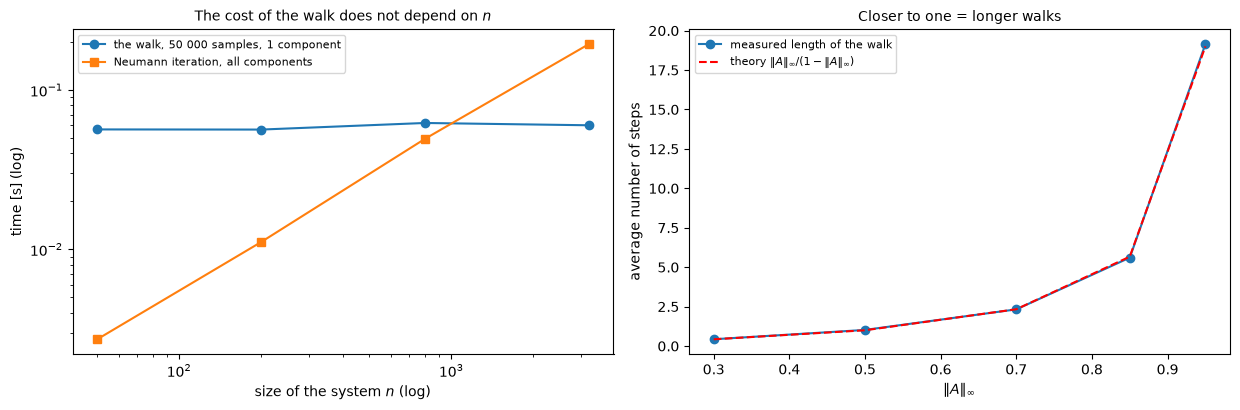

In [3]:
print(f"{'n':>7s} {'walk (1 component)':>26s} {'iteration (all)':>20s} {'reference x[3]':>16s}")
ns, t_mc, t_it = [], [], []
for n in (50, 200, 800, 3200):
    A, b = random_system(n, density=min(1.0, 8 / n), norm=0.7, seed=11)

    t0 = time.perf_counter()
    m, se = estimate(A, b, 3, 50_000)
    time_mc = time.perf_counter() - t0

    t0 = time.perf_counter()
    x = neumann_iteration(A, b, steps=120)
    time_it = time.perf_counter() - t0

    ns.append(n); t_mc.append(time_mc); t_it.append(time_it)
    print(f"{n:>7d} {m:>14.5f} +- {se:<5.5f} {time_mc:>6.2f} s {time_it:>13.2f} s {x[3]:>16.5f}")
    assert abs(m - x[3]) < 5 * se

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
ax.loglog(ns, t_mc, "o-", label="the walk, 50 000 samples, 1 component")
ax.loglog(ns, t_it, "s-", label="Neumann iteration, all components")
ax.set_xlabel("size of the system $n$ (log)")
ax.set_ylabel("time [s] (log)")
ax.set_title("The cost of the walk does not depend on $n$", fontsize=10)
ax.legend(fontsize=8)

# how the length of the walk depends on the norm
ax = axes[1]
norms = (0.3, 0.5, 0.7, 0.85, 0.95)
lengths, errors = [], []
for norm in norms:
    A, b = random_system(100, density=0.1, norm=norm, seed=5)
    total = 0
    for _ in range(20_000):
        s, steps = 3, 0
        while True:
            u, cum, nxt = random.random(), 0.0, None
            for j, a in A[s]:
                cum += abs(a)
                if u < cum:
                    nxt = j
                    break
            if nxt is None:
                break
            s = nxt
            steps += 1
        total += steps
    lengths.append(total / 20_000)
    errors.append(estimate(A, b, 3, 20_000)[1])
ax.plot(norms, lengths, "o-", label="measured length of the walk")
ax.plot(norms, [1 / (1 - x_) - 1 for x_ in norms], "r--", label=r"theory $\|A\|_\infty/(1-\|A\|_\infty)$")
ax.set_xlabel(r"$\|A\|_\infty$")
ax.set_ylabel("average number of steps")
ax.set_title("Closer to one = longer walks", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

The left-hand plot shows the main point: the time of the walk is a **horizontal line** — the system
can grow arbitrarily and the cost of one component does not change. The iteration grows with the size
of the system.

The right-hand plot shows where the limit of usability lies. The length of the walk grows like
$1/(1-\|A\|_\infty)$, so for a matrix close to the edge of convergence the walks are long and the
method bogs down. It is the same trouble iterative methods have — it just shows up differently.

**So when to reach for a walk:**

| | |
|---|---|
| ✓ | an enormous sparse system, and you want a few components |
| ✓ | the matrix cannot be assembled, but you can compute $a_{ij}$ on demand |
| ✓ | low accuracy is enough (the error falls like $1/\sqrt N$; for three correct digits you need $\sim 10^6$ walks) |
| ✗ | you want the whole solution |
| ✗ | you want high accuracy |
| ✗ | $\rho(A)$ is close to 1 |

A historical note: this very problem stood at the birth of the method. Von Neumann and Ulam proposed
it in the 1940s at Los Alamos, and the name "Monte Carlo" comes from the same time and the same place.

## Summary

| Concept | What to remember |
|---------|------------------|
| The iterative form | $x = Ax + b$, the solution $x = \sum_k A^k b$ (the Neumann series) |
| The condition | $\rho(A) < 1$; $\|A\|_\infty < 1$ suffices |
| A path = a term of the series | $i \to j_1 \to \dots \to j_k$ corresponds to $a_{ij_1}\cdots a_{j_{k-1}j_k}b_{j_k}$ |
| The estimator | $\xi = \sum_k W_k b_{s_k}$, $W_k = W_{k-1}a_{st}/p_{st}$ |
| The clever choice of $p$ | $p_{st} = \lvert a_{st}\rvert \Rightarrow W = \pm 1$, the weights do not spread out |
| The length of the walk | on average $\|A\|_\infty/(1 - \|A\|_\infty)$ steps |
| The main advantage | the cost **does not depend on $n$** and only one component is computed |

### Try it yourself

1. Try a uniform $p_{st}$ instead of $\lvert a_{st}\rvert$. The estimate stays unbiased — by how much
   does the variance grow?
2. Estimate the functional $(h, x) = \sum_i h_i x_i$ instead of a single component: it is enough to
   start the walk at a random $i$ with probability proportional to $h_i$.
3. Construct a matrix with $\|A\|_\infty = 1.05$ and show that the walks do not terminate and the
   estimate diverges.
4. For $\|A\|_\infty = 0.9$, measure how many walks are needed for three correct digits. Compare that
   with the cost of the Neumann iteration.
5. Compute $A^{-1}_{ij}$ (a single element of the inverse) by substituting the $j$-th unit vector for
   $b$.